# Amazon UK Product Insights

In [37]:
import pandas as pd
import numpy as np
import plotly as pt
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

amazon_raw = pd.read_csv("amz_uk_price_prediction_dataset.csv")

### 0. Dataset Exploration.

Lets explore the dataset a little bit.

First, we copy into a new dataframe to avoid messing with the original data.

In [20]:
amazon = amazon_raw.copy()

Then, we can review the features of the dataset and the amount of nulls per collumn

In [11]:
#Feature info
amazon.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [12]:
#Nulls per feature
amazon.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In this case, we can see that the datatypes seem to fit the feature nature (there are no numerical variables with string type, for example). Also, there are no features with null values.

Now, we can examine wether the dataset has duplicates, specially for the uid column, which we assume could be treated as a primary key.

In [15]:
print("Exact duplicate rows:", amazon.duplicated().sum())
print("Duplicated ids:", amazon["uid"].duplicated().sum())

Exact duplicate rows: 0
Duplicated ids: 0


As we can see, there are no duplicates. We will proceed to set the index of the dataset to the natural candidate: the uid column. In this case, we will maintain the original column in place.

In [21]:
amazon.set_index("uid", drop=False, inplace=True)

In [22]:
amazon.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
uid,,,,,,,,,
1,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
2,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
3,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
4,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
5,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Understanding Product Categories

Let's see how can we answer the following business question: **What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?**

We can start by analizing the frequency of each category. This means counting the occurence of each value in category and computing it's relative frequency compared to the total.

But before, let's see how many different categories are there:

In [31]:
amazon["category"].nunique()

296

We can see there is a lot of categories, so it would be useful to focus on the top 5 of them in the frequency table we are going to generate.

In [44]:
freq = pd.DataFrame({
    "count": amazon["category"].value_counts(),
    "share_%": amazon["category"].value_counts(normalize=True).mul(100).round(1),
})

freq.head(5)

,count,share_%
category,,
Sports & Outdoors,836265,34.2
Beauty,19312,0.8
"Handmade Clothing, Shoes & Accessories",19229,0.8
Bath & Body,19092,0.8
Birthday Gifts,18978,0.8


As we can see, "Sports & Outdoors" is by far the most frequent value. But let's visualize it in order to get a more visual understanding of the gap between different categories.

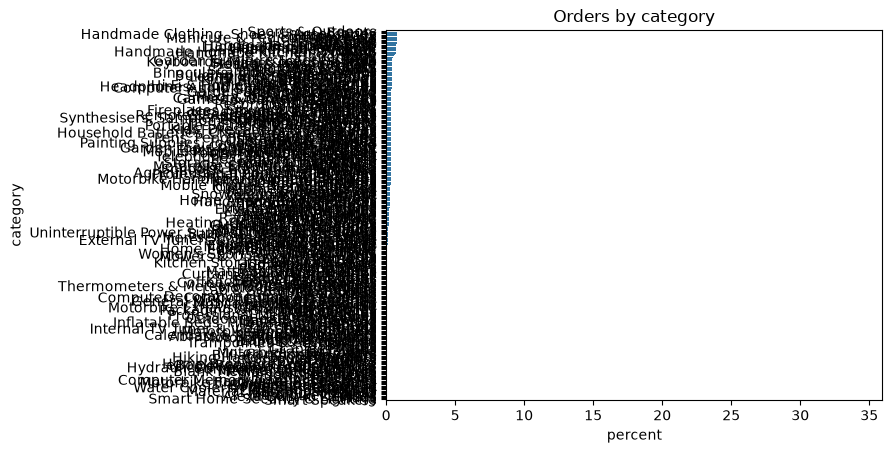

In [77]:
indexes = amazon["category"].value_counts().index
sns.countplot(data=amazon, y="category", order=indexes, stat="percent")
plt.title("Orders by category")
plt.show()

Is it possible to analize anything if we plot that many categories? Clearly not, so let's focus on the top 5 of them.

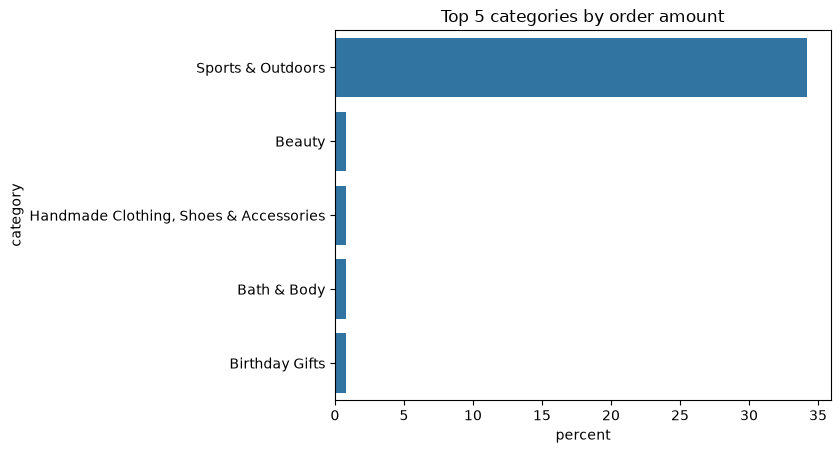

In [89]:
indexes = amazon["category"].value_counts().head(5).index
sns.countplot(data=amazon, y="category", order=indexes, stat="percent")
plt.title("Top 5 categories by order amount")
plt.show()

Another way to visualize it is with a pie chart:

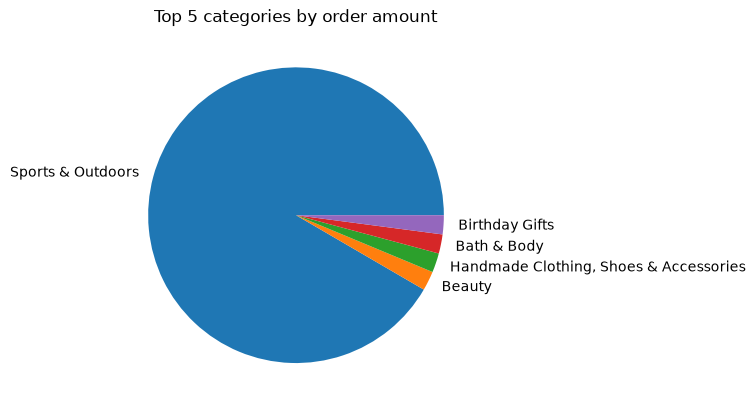

In [90]:
values = amazon["category"].value_counts().head(5)
labels = values.index
plt.pie(x=values, labels=labels)
plt.title("Top 5 categories by order amount")
plt.show()

This shows even better how overrepresented Sports & Outdoors category is compared to the rest

### Part 2: Delving into Product Pricing

Let's now try to answer the following question: **How are products priced on Amazon UK, and are there specific price points or ranges that are more common?**

We can start analizing the of the price feature:

In [204]:
def centrality(s):
    return pd.Series({
        "mean": s.mean().round(2),
        "median": s.median().round(2),
        "mode(s)": list(s.mode().round(2)),
        "max": s.max().round(2),
        "min": s.min().round(2),
    })

pd.DataFrame({
    "Price": centrality(amazon["price"])
})


,Price
mean,89.24
median,19.09
mode(s),[9.99]
max,100000.0
min,0.0


As we can see, the mean is significantly larger than the median, so we can assume there are extreme values distorting the mean. The next step we should take is to analyze the dispersion of this feature.

In [99]:
def dispersion(s):
    return pd.Series({
        "variance": s.var(),
        "std": s.std(),
        "range": s.max() - s.min(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "coef_variation": s.std() / s.mean(),
    }).round(2)

pd.DataFrame({
    "Price": dispersion(amazon["price"])
})

,Price
variance,119445.49
std,345.61
range,100000.00
IQR,36.00
coef_variation,3.87


At a glance we can see that there is apparently a huge dispersion in the values of the price feature. For example, if the prices were in euros, the typical product is around 345€ more expensive than the mean of 89€, like the typical price is around 4 times bigger than the average price, as we can see in the coefficient of variation. Also, we can observe that the range is 10.0000. All seems to indicate that there are huge differences between prices.

But let's plot it to be able to more easly and visually 

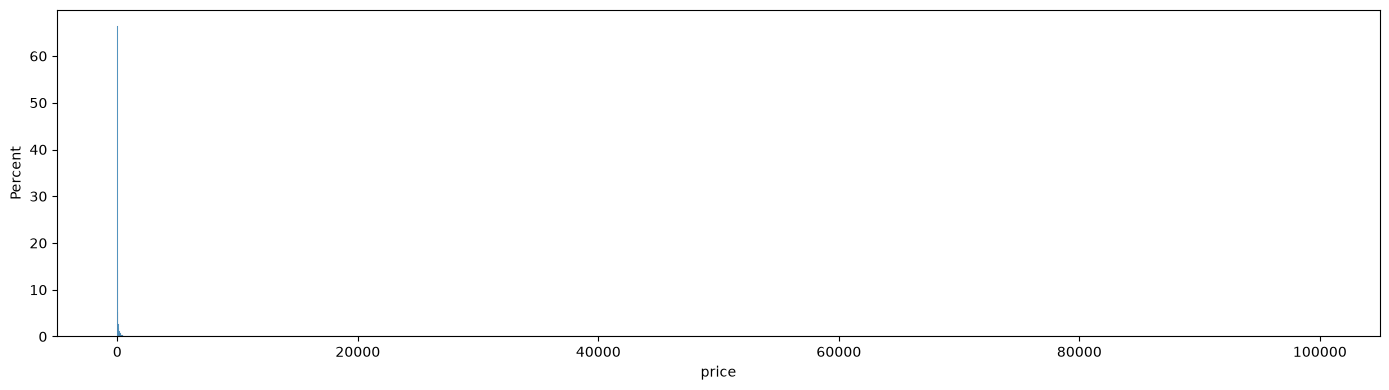

In [114]:
fig, axes = plt.subplots(1, figsize=(14, 4))
sns.histplot(amazon["price"], ax=axes, stat="percent")
ax.set_title(f"Price")
plt.tight_layout()
plt.show()

But the range is so big, that we can barely see anything at this scale. So, what we could do next is to break down the sclae in different sub-scales. For example, in multiples of 10. So we'll create 4 histoplots for prices less than 100, between 100 and 1.000, between 1.000 and 10.000 and for more than 10.000.

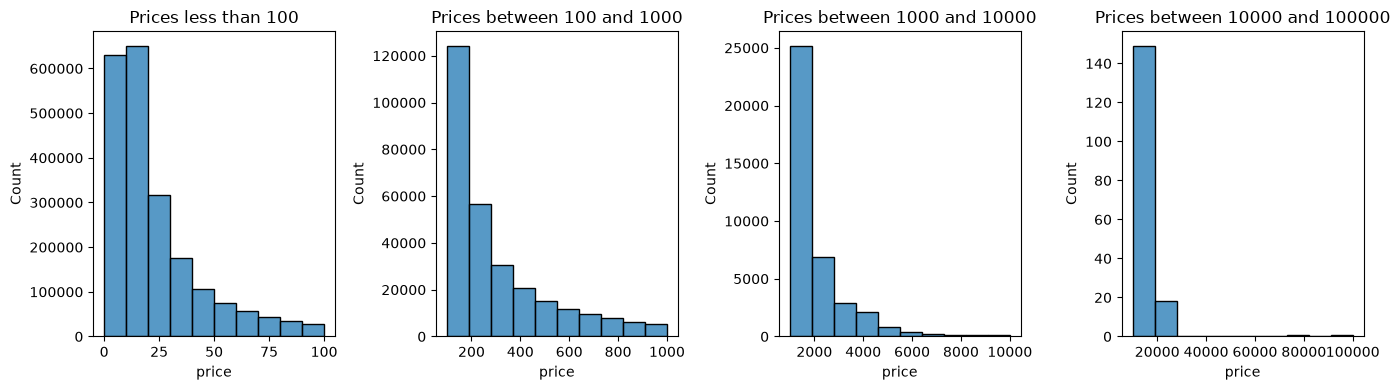

In [179]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

amazon_range_a = amazon[amazon['price'] <= 100]
amazon_range_b = amazon[amazon['price'].between(100,1000)]
amazon_range_c = amazon[amazon['price'].between(1000,10000)]
amazon_range_d = amazon[amazon['price'].between(10000,100000)]

amazon_ranges = [amazon_range_a, amazon_range_b, amazon_range_c, amazon_range_d]
range_lables = ["less than 100","between 100 and 1000","between 1000 and 10000","between 10000 and 100000"]
n = 0

for ax in axes:
    sns.histplot(amazon_ranges[n]["price"], ax=ax, bins=10)
    ax.set_title(f"Prices {range_lables[n]}")
    n+=1

plt.tight_layout()
plt.show()

Also, we could plot the original histoplot in a logarithmic scale:

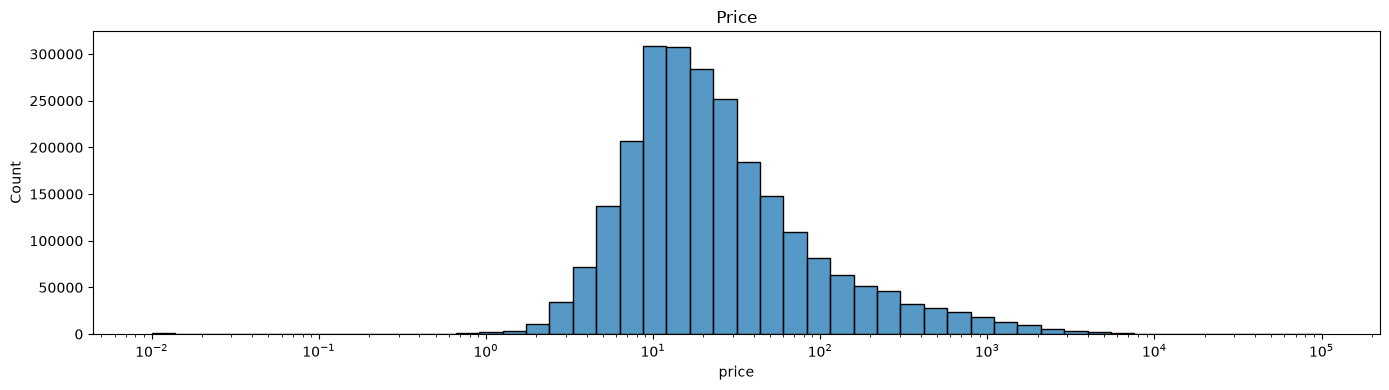

In [182]:
fig, axes = plt.subplots(1, figsize=(14, 4))
sns.histplot(amazon["price"], ax=axes,bins=50, log_scale=True)
axes.set_title(f"Price distribution in logarithmic scale")
plt.tight_layout()
plt.show()

Let's try a different approach. A box plot would show us more visually if there are many outliers. Again, we'll use a logarithmic scale because otherwise the graph would be unreadable.

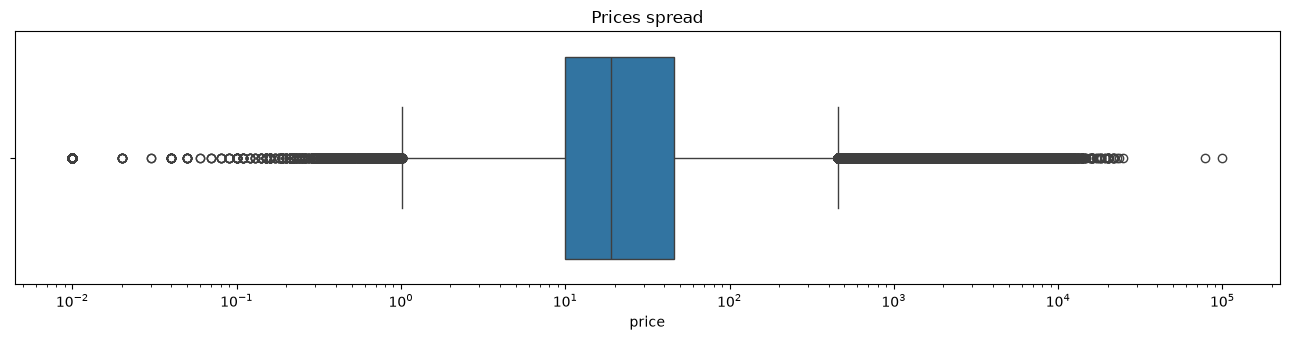

In [186]:
fig, axes = plt.subplots(1, figsize=(13, 3.5))
sns.boxplot(x=amazon["price"], ax=axes, log_scale=True).set_title("Prices spread")
plt.tight_layout()
plt.show()

We can observe a significan amount of outliers. Some of them goes even up to proces around 100.000, when the median is about 20.

### Part 3: Unpacking Product Ratings

Finally, we need to answer a last question: **How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?**

First of all, let's obtain the centrality measures of the stars feature.

In [207]:
pd.DataFrame({
    "Ratings": centrality(amazon["stars"])
})

,Ratings
mean,2.15
median,0.0
mode(s),[0.0]
max,5.0
min,0.0


As the median is 0.0, it seems that a lot of people is not reviewing the products they buy. We can it more clearly with a frequency table:

In [220]:
pd.DataFrame({
    "count": amazon["stars"].value_counts(),
    "share_%": amazon["stars"].value_counts(normalize=True).mul(100).round(1),
}).head(10)

,count,share_%
stars,,
0.0,1225641,50.2
4.5,151577,6.2
4.6,136995,5.6
4.4,136165,5.6
5.0,128492,5.3
4.3,112564,4.6
4.7,94566,3.9
4.2,86871,3.6
4.0,66089,2.7


From this, we can see thant the majority of people are probably not rating the products, while the majority of the pople that rates gives it a fairly good rating, above 4 stars. Let's now analyze the dispersion.

In [208]:
pd.DataFrame({
    "Ratings": dispersion(amazon["stars"])
})

,Ratings
variance,4.82
std,2.19
range,5.00
IQR,4.40
coef_variation,1.02


We can see that there is a huge IQR, nearly as big as the range, so it points to the existence of outliers, which as we seen in the frequency table, are mostly represented by the 0.0 ratings.

We can confirm this looking at the skweness and kurtosis of the distribution.

In [221]:
skew = amazon["stars"].skew()
kurt = amazon["stars"].kurt()
print(f"Skewness: {skew}, kurtosis {kurt}.")

Skewness: 0.08120735761080881, kurtosis -1.9260061280432994.


We have a very little skewness, so the distribution seems mostly symmetric and the kurtosis indicates a flattened distribution, without much tails. What if we create an histoplot with stars feature?

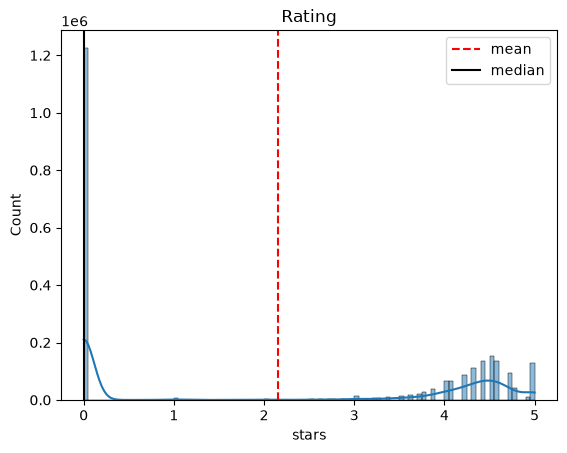

In [234]:
ax = sns.histplot(amazon["stars"], bins=100, kde=True)
ax.axvline(amazon["stars"].mean(), color="red", linestyle="--", label="mean")
ax.axvline(amazon["stars"].median(), color="black", label="median")
ax.legend()
ax.set_title("Rating")
plt.show()

This would confirm our initial findings. Most of ratings are concentrated at 0.0 and between 4 and 5. But visually it would look like it have heavy tails and is left-skewed.

### Bonus: Alternate scenario

Let's a little experiment. What if we interpret the 0.0 ratings as lack of rating instead of considering it the lowest possible rating? Then, we might want to remove those ratings as they are distorting the statistics. What would the picture be if we remove the ratings of 0.0 stars? Will the statistics change a lot? Let's check it out

In [215]:
amazon_clean_ratings = amazon[amazon["stars"] > 0.0].copy()

In [218]:
pd.DataFrame({
    "Clean Ratings": centrality(amazon_clean_ratings["stars"])
})

,Clean Ratings
mean,4.32
median,4.4
mode(s),[4.5]
max,5.0
min,1.0


Now, we se that the mean is very close tot he median, so we can guess that the dispersion will be very little.

In [219]:
pd.DataFrame({
    "Clean Ratings": dispersion(amazon_clean_ratings["stars"])
})

,Clean Ratings
variance,0.31
std,0.56
range,4.00
IQR,0.50
coef_variation,0.13


Here we are confirming our previous finding. The standard deviation is tiny, as it is the IQR. It seams the spread is pretty low

In [238]:
pd.DataFrame({
    "count": amazon_clean_ratings["stars"].value_counts(),
    "share_%": amazon_clean_ratings["stars"].value_counts(normalize=True).mul(100).round(1),
}).head(10)

,count,share_%
stars,,
4.5,151577,12.4
4.6,136995,11.2
4.4,136165,11.2
5.0,128492,10.5
4.3,112564,9.2
4.7,94566,7.8
4.2,86871,7.1
4.0,66089,5.4
4.1,65115,5.3


Again, a frequency table confirms that the majority of the ratings are between 4 and 5. But let's see the kurtosis and skewness:

In [240]:
skew = amazon_clean_ratings["stars"].skew()
kurt = amazon_clean_ratings["stars"].kurt()
print(f"Skewness: {skew}, kurtosis {kurt}.")

Skewness: -2.379568112212799, kurtosis 9.78193769066435.


According to this, we se that the distribution is highly assimetric and kurtosis, on the other hand, indicates heave tails and exteme values. It makes sense given that the majority of the ratings concentrate between 4 and 5. 

But let's visualize everything we've got. Just for fun.

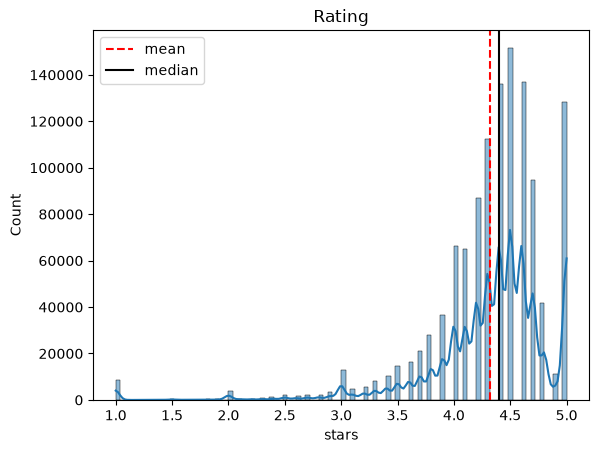

In [241]:
ax = sns.histplot(amazon_clean_ratings["stars"], bins=100, kde=True)
ax.axvline(amazon_clean_ratings["stars"].mean(), color="red", linestyle="--", label="mean")
ax.axvline(amazon_clean_ratings["stars"].median(), color="black", label="median")
ax.legend()
ax.set_title("Rating")
plt.show()

We clearly see a highly right-skewed distribution. Now we can compare both datasets, with and without 0.0 ratings:

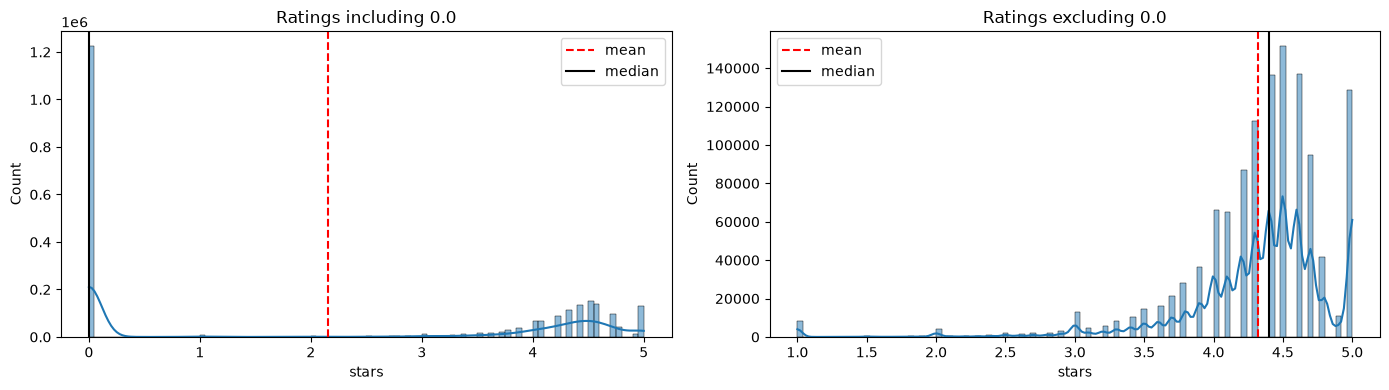

In [242]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(amazon["stars"], bins=100, ax=axes[0], kde=True)
axes[0].axvline(amazon["stars"].mean(), color="red", linestyle="--", label="mean")
axes[0].axvline(amazon["stars"].median(), color="black", label="median")
axes[0].legend()
axes[0].set_title(f"Ratings including 0.0")

sns.histplot(amazon_clean_ratings["stars"], bins=100, ax=axes[1], kde=True)
axes[1].axvline(amazon_clean_ratings["stars"].mean(), color="red", linestyle="--", label="mean")
axes[1].axvline(amazon_clean_ratings["stars"].median(), color="black", label="median")
axes[1].legend()
axes[1].set_title(f"Ratings excluding 0.0")

plt.tight_layout()
plt.show()